# ERCOT - Outage DATA

1. archive have only forward outage data, live have historical values
2. compare to see the drift between 1 hour ahead and live data

## 1. Imports & paths

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

PROJECT_ROOT = Path('../..').resolve()
ARCHIVE_PATH = PROJECT_ROOT / '01_data' / '2_cleaned' / 'outage' / 'archive_1h_ahead_outage_20210101_2026_0924.parquet'
LIVE_PATH    = PROJECT_ROOT / '01_data' / '1.2_raw_api' / 'outage' / 'outage_cap_20231210_20260923.parquet'
OUT_DIR      = PROJECT_ROOT / '01_data' / '2_cleaned' / 'outage'
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load & inspect

In [3]:
df_archive = pd.read_parquet(ARCHIVE_PATH)
df_live = pd.read_parquet(LIVE_PATH)

In [5]:
# profiling table
summary = pd.DataFrame({
    'data_types': df_live.dtypes,
    'n_missing': [df_live[col].isna().sum() for col in df_live.columns],
    'missing_rate_%': [round(df_live[col].isna().mean()*100, 2) for col in df_live.columns],
    'n_unique': [df_live[col].nunique() for col in df_live.columns],
    'sample_entries': [list(df_live[col].unique()[:3]) for col in df_live.columns]
})
summary

,data_types,n_missing,missing_rate_%,n_unique,sample_entries
postedDatetime,str,0,0.0,24321,"[2026-09-20T10:00:48, 2026-09-20T09:00:49, 202..."
operatingDate,str,0,0.0,1016,"[2026-09-20, 2026-09-19, 2026-09-18]"
hourEnding,int64,0,0.0,24,"[1, 2, 3]"
totalResourceMWZoneSouth,int64,0,0.0,12542,"[3927, 3928, 3728]"
totalResourceMWZoneNorth,int64,0,0.0,12929,"[4945, 4905, 5785]"
totalResourceMWZoneWest,int64,0,0.0,2323,"[648, 649, 638]"
totalResourceMWZoneHouston,int64,0,0.0,7419,"[1882, 1763, 1653]"


In [6]:
df_live.head()

,postedDatetime,operatingDate,hourEnding,totalResourceMWZoneSouth,totalResourceMWZoneNorth,totalResourceMWZoneWest,totalResourceMWZoneHouston
0,2026-09-20T10:00:48,2026-09-20,1,3927,4945,648,1882
1,2026-09-20T10:00:48,2026-09-20,2,3927,4945,648,1882
2,2026-09-20T10:00:48,2026-09-20,3,3927,4945,648,1882
3,2026-09-20T10:00:48,2026-09-20,4,3927,4945,648,1882
4,2026-09-20T10:00:48,2026-09-20,5,3927,4945,648,1763


## 2.5 Cleaning (Datetime column and total outage)

In [13]:
zones = ['totalResourceMWZoneSouth', 'totalResourceMWZoneNorth',
         'totalResourceMWZoneWest', 'totalResourceMWZoneHouston']

live = df_live.drop_duplicates(['postedDatetime', 'operatingDate', 'hourEnding']).copy()
live['totalResourceMW'] = live[zones].sum(axis=1)
live['datetime'] = pd.to_datetime(live['operatingDate']) + pd.to_timedelta(live['hourEnding'], unit='h')
live['pdt'] = pd.to_datetime(live['postedDatetime'], format='ISO8601')

live = live[live.groupby('postedDatetime')['totalResourceMW'].transform('sum') != 0]

last_hour = live['pdt'].max().ceil('h')
h1_live = (live[(live['pdt'] < live['datetime']) & (live['datetime'] <= last_hour)]
             .sort_values('pdt')
             .drop_duplicates('datetime', keep='last')
             .sort_values('datetime')
             .reset_index(drop=True))

h1_live['lead_min'] = (h1_live['datetime'] - h1_live['pdt']).dt.total_seconds() / 60
print(len(h1_live), h1_live['datetime'].is_unique)
print(h1_live['lead_min'].describe())

24332 True
count    24332.000000
mean        58.706180
std          1.692993
min         51.583333
25%         58.800000
50%         58.966667
75%         59.166667
max        119.300000
Name: lead_min, dtype: float64


In [26]:
df = df.filter(['datetime', 'totalResourceMW'])
df.to_parquet(OUT_DIR / 'archive_1h_ahead_outage_20210101_2026_0924.parquet')

## 3. Summary statistics

In [22]:
print('=== ERCOT — Hourly Outage Statistics ===')
df.describe()

=== ERCOT — Hourly Outage Statistics ===


,datetime,totalResourceMW
count,9541728,9.541728e+06
mean,2023-11-26 09:52:01.046754,1.210907e+04
min,2021-01-01 01:00:00,0.000000e+00
25%,2022-06-27 08:00:00,5.482000e+03
50%,2023-11-27 03:00:00,9.511000e+03
75%,2025-04-27 22:00:00,1.874100e+04
max,2026-10-01 23:00:00,3.534400e+04
std,NaN,7.745494e+03


## 4. Time Series Line Chart

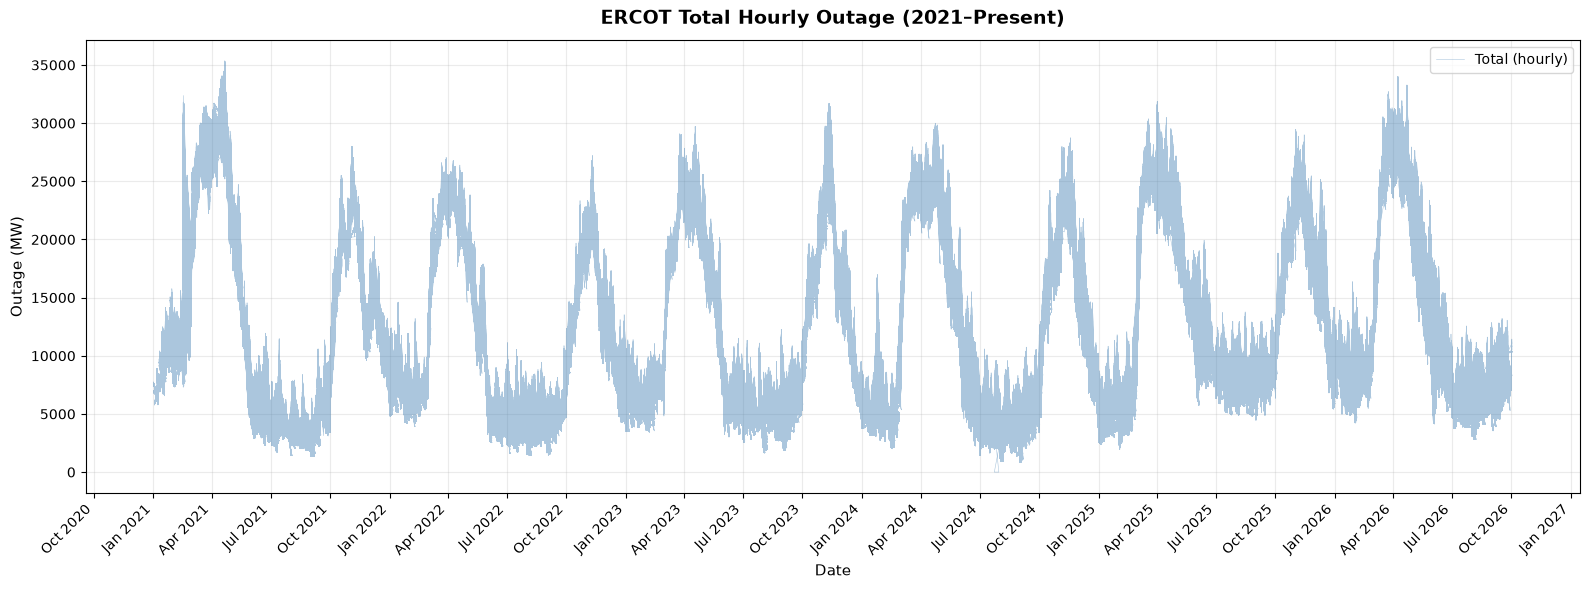

In [24]:
# 7-day rolling average for trend overlay
df = df.copy()

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(df['datetime'], df['totalResourceMW'],
        color='steelblue', linewidth=0.4, alpha=0.45, label='Total (hourly)')

ax.set_title('ERCOT Total Hourly Outage (2021–Present)',
             fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Outage (MW)', fontsize=11)
ax.set_xlabel('Date', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.25)

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, ha='right')

fig.tight_layout()
plt.show()

In [25]:
# compair with live

df_live

,postedDatetime,operatingDate,hourEnding,totalResourceMWZoneSouth,totalResourceMWZoneNorth,totalResourceMWZoneWest,totalResourceMWZoneHouston
0,2026-09-20T10:00:48,2026-09-20,1,3927,4945,648,1882
1,2026-09-20T10:00:48,2026-09-20,2,3927,4945,648,1882
2,2026-09-20T10:00:48,2026-09-20,3,3927,4945,648,1882
3,2026-09-20T10:00:48,2026-09-20,4,3927,4945,648,1882
4,2026-09-20T10:00:48,2026-09-20,5,3927,4945,648,1763
...,...,...,...,...,...,...,...
4669763,2023-12-11T15:03:49,2023-12-11,21,7492,3844,548,3588
4669764,2023-12-11T15:03:49,2023-12-11,22,7492,3844,548,3588
4669765,2023-12-11T15:03:49,2023-12-11,23,7492,3844,548,3588
4669766,2023-12-11T15:03:49,2023-12-11,24,7225,4003,548,3588


## 5. Save processed time series

In [ ]:
out_parquet = OUT_DIR / 'outage_20210101_20260926.parquet'
df.to_parquet(out_parquet, index=False)

In [8]:
aggregated = df.copy()
aggregated.rename(columns={'total': 'total_load'}, inplace=True)
aggregated = aggregated.filter(['datetime', 'total_load'])
aggregated.to_csv(OUT_DIR / 'total_load_20201231_20260526.csv', index=False)
aggregated

,datetime,total_load
0,2020-12-31 01:00:00,39174.39
1,2020-12-31 02:00:00,38284.84
2,2020-12-31 03:00:00,37776.69
3,2020-12-31 04:00:00,37781.84
4,2020-12-31 05:00:00,38455.69
...,...,...
47314,2026-05-26 20:00:00,66009.13
47315,2026-05-26 21:00:00,63250.91
47316,2026-05-26 22:00:00,60728.67
47317,2026-05-26 23:00:00,56995.91
